N=1024 P= 1  Median=0.2234 s  Min=0.2217 s  Speedup=1.00  Effizienz=100%
N=1024 P= 4  Median=0.0709 s  Min=0.0701 s  Speedup=3.15  Effizienz=79%


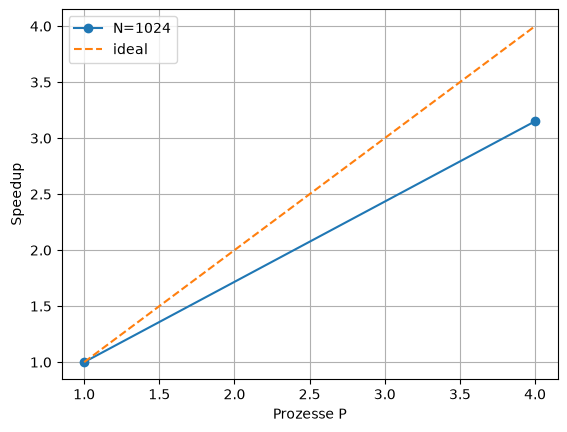

In [3]:
import numpy as np, matplotlib.pyplot as plt
datei = '/home/itmvs/waerme/kadan/test20.csv'
d = np.genfromtxt(datei, delimiter=',', names=True, dtype=None, encoding=None)
for N in np.unique(d['N']):
    Ps = np.unique(d['P'][d['N'] == N])
    med = np.array([np.median(d['zeit_s'][(d['N'] == N) & (d['P'] == P)]) for P in Ps])
    mn  = np.array([np.min(d['zeit_s'][(d['N'] == N) & (d['P'] == P)]) for P in Ps])
    S = med[0] / med
    E = S / Ps
    for P, t, m, s, e in zip(Ps, med, mn, S, E):
        print(f"N={N} P={P:2d}  Median={t:.4f} s  Min={m:.4f} s  Speedup={s:.2f}  Effizienz={e:.0%}")
    plt.plot(Ps, S, 'o-', label=f'N={N}')
plt.plot([1, Ps.max()], [1, Ps.max()], '--', label='ideal')
plt.xlabel('Prozesse P'); plt.ylabel('Speedup'); plt.legend(); plt.grid(True)
plt.savefig('/home/itmvs/waerme/kadan/speedup_test.png', dpi=150)
plt.show()

In [5]:
import math
def ki_median(werte, z=1.96):
    # 95-%-KI des Medians nach Hoefler & Belli (2015), Abschn. 3.1.3
    x = np.sort(np.asarray(werte)); n = len(x)
    lo = math.floor((n - z * math.sqrt(n)) / 2)
    hi = math.ceil(1 + (n + z * math.sqrt(n)) / 2)
    if lo < 1 or hi > n:
        return None
    return x[lo - 1], x[hi - 1]

for N in np.unique(d['N']):
    for P in np.unique(d['P'][d['N'] == N]):
        t = d['zeit_s'][(d['N'] == N) & (d['P'] == P)]
        ki = ki_median(t)
        text = f"{ki[0]:.4f} bis {ki[1]:.4f} s" if ki else "zu wenige Messungen"
        print(f"N={N} P={P:2d}  n={len(t)}  Median={np.median(t):.4f} s  95%-KI: {text}")

N=1024 P= 1  n=20  Median=0.2234 s  95%-KI: 0.2222 bis 0.2243 s
N=1024 P= 4  n=20  Median=0.0709 s  95%-KI: 0.0703 bis 0.0712 s


In [6]:
b = np.genfromtxt('/home/itmvs/waerme/kadan/baseline.csv', delimiter=',', names=True, dtype=None, encoding=None)
med = {}
for m in np.unique(b['modus']):
    for N in np.unique(b['N'][b['modus'] == m]):
        sel = (b['modus'] == m) & (b['N'] == N)
        t = b['zeit_s'][sel]
        ki = ki_median(t)
        med[(m, N)] = np.median(t)
        upd = (N - 2)**2 * 200 / np.median(t) / 1e6
        gleich = len(np.unique(b['summe'][sel])) == 1
        print(f"{m:5s} N={N}  n={len(t)}  Median={np.median(t):.4f} s  95%-KI: {ki[0]:.4f} bis {ki[1]:.4f} s  {upd:.0f} Mio. Updates/s  Summen gleich: {gleich}")
print(f"NumPy / Numba bei N=2048: Faktor {med[('numpy', 2048)] / med[('numba', 2048)]:.1f}")

numba N=2048  n=20  Median=1.3309 s  95%-KI: 1.3172 bis 1.3435 s  629 Mio. Updates/s  Summen gleich: True
numba N=4096  n=20  Median=5.1694 s  95%-KI: 5.1251 bis 5.2254 s  648 Mio. Updates/s  Summen gleich: True
numpy N=2048  n=20  Median=10.7618 s  95%-KI: 10.5780 bis 10.8477 s  78 Mio. Updates/s  Summen gleich: True
NumPy / Numba bei N=2048: Faktor 8.1


--- N=2048  Summen bei allen P gleich: True
P= 1  n=20  Median=2.2092 s  KI 2.1496-2.2121  Speedup= 1.00  Effizienz=100%  Komm.max=0.0036 s
P= 2  n=20  Median=0.7244 s  KI 0.7159-0.7262  Speedup= 3.05  Effizienz=152%  Komm.max=0.0170 s
P= 4  n=20  Median=0.5034 s  KI 0.5007-0.5144  Speedup= 4.39  Effizienz=110%  Komm.max=0.0291 s
P= 8  n=20  Median=0.4577 s  KI 0.4533-0.4620  Speedup= 4.83  Effizienz= 60%  Komm.max=0.0394 s
P=12  n=20  Median=0.4421 s  KI 0.4413-0.4429  Speedup= 5.00  Effizienz= 42%  Komm.max=0.0183 s
P=24  n=20  Median=0.1777 s  KI 0.1742-0.1839  Speedup=12.43  Effizienz= 52%  Komm.max=0.1129 s
P=36  n=20  Median=0.1561 s  KI 0.1450-0.1588  Speedup=14.15  Effizienz= 39%  Komm.max=0.1188 s
P=48  n=20  Median=0.1409 s  KI 0.1367-0.1453  Speedup=15.67  Effizienz= 33%  Komm.max=0.1129 s
--- N=4096  Summen bei allen P gleich: True
P= 1  n=20  Median=5.1909 s  KI 5.1857-5.1949  Speedup= 1.00  Effizienz=100%  Komm.max=0.0040 s
P= 2  n=20  Median=2.8003 s  KI 2.7887-2.8045  S

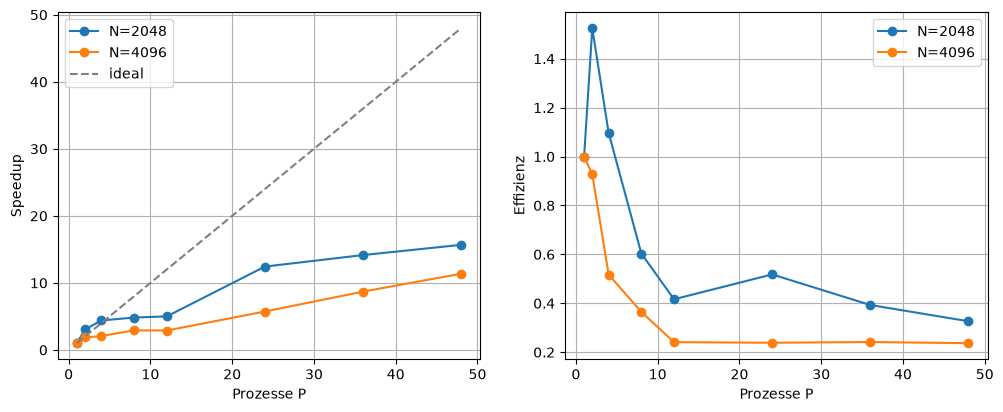

In [7]:
s = np.genfromtxt('/home/itmvs/waerme/results/a_strong_2026-10-28.csv', delimiter=',', names=True, dtype=None, encoding=None)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for N in np.unique(s['N']):
    Ps = np.unique(s['P'][s['N'] == N])
    print(f"--- N={N}  Summen bei allen P gleich: {len(np.unique(s['summe'][s['N'] == N])) == 1}")
    meds = []
    for P in Ps:
        sel = (s['N'] == N) & (s['P'] == P)
        t = s['zeit_s'][sel]; ki = ki_median(t); m = np.median(t); meds.append(m)
        print(f"P={P:2d}  n={len(t)}  Median={m:.4f} s  KI {ki[0]:.4f}-{ki[1]:.4f}  Speedup={meds[0]/m:5.2f}  Effizienz={meds[0]/m/P:4.0%}  Komm.max={np.median(s['komm_max_s'][sel]):.4f} s")
    S = meds[0] / np.array(meds)
    ax[0].plot(Ps, S, 'o-', label=f'N={N}'); ax[1].plot(Ps, S / Ps, 'o-', label=f'N={N}')
ax[0].plot([1, 48], [1, 48], '--', color='gray', label='ideal')
ax[0].set_xlabel('Prozesse P'); ax[0].set_ylabel('Speedup'); ax[0].legend(); ax[0].grid(True)
ax[1].set_xlabel('Prozesse P'); ax[1].set_ylabel('Effizienz'); ax[1].legend(); ax[1].grid(True)
plt.savefig('/home/itmvs/waerme/kadan/a_strong_2026-10-28.png', dpi=150); plt.show()

In [8]:
w = np.genfromtxt('/home/itmvs/waerme/results/a_weak_2026-10-28.csv', delimiter=',', names=True, dtype=None, encoding=None)
t1 = None
for N, P in [(4096, 12), (5793, 24), (8192, 48)]:
    sel = (w['N'] == N) & (w['P'] == P)
    t = w['zeit_s'][sel]; ki = ki_median(t); m = np.median(t)
    t1 = m if t1 is None else t1
    upd = (N - 2)**2 * 200 / m / 1e6
    print(f"Rechner={P//12}  P={P}  N={N}  n={len(t)}  Median={m:.4f} s  KI {ki[0]:.4f}-{ki[1]:.4f}  Effizienz={t1/m:4.0%}  {upd:.0f} Mio. Updates/s  Summen gleich: {len(np.unique(w['summe'][sel])) == 1}")

Rechner=1  P=12  N=4096  n=20  Median=1.8174 s  KI 1.7869-1.8455  Effizienz=100%  1845 Mio. Updates/s  Summen gleich: True
Rechner=2  P=24  N=5793  n=20  Median=1.7652 s  KI 1.7560-1.7807  Effizienz=103%  3800 Mio. Updates/s  Summen gleich: True
Rechner=4  P=48  N=8192  n=20  Median=1.8200 s  KI 1.8156-1.8237  Effizienz=100%  7371 Mio. Updates/s  Summen gleich: True


In [9]:
for N, P in [(2048, 1), (2048, 2), (4096, 2), (4096, 4)]:
    sel = (s['N'] == N) & (s['P'] == P)
    print(f"N={N} P={P}:", np.round(np.sort(s['zeit_s'][sel]), 3))

N=2048 P=1: [1.324 1.327 1.331 1.339 2.15  2.154 2.206 2.207 2.209 2.209 2.21  2.21
 2.211 2.212 2.212 2.212 2.213 2.213 2.213 2.214]
N=2048 P=2: [0.712 0.712 0.714 0.716 0.716 0.717 0.721 0.723 0.723 0.724 0.725 0.725
 0.725 0.726 0.726 0.726 0.727 0.732 0.732 0.732]
N=4096 P=2: [2.772 2.775 2.786 2.789 2.789 2.79  2.799 2.799 2.799 2.8   2.8   2.802
 2.803 2.803 2.804 2.804 2.811 2.811 2.824 2.836]
N=4096 P=4: [1.909 1.91  1.915 1.921 1.929 1.947 1.974 1.974 2.502 2.506 2.51  2.513
 2.515 2.52  2.524 2.533 2.541 2.557 2.588 2.589]


In [10]:
import numpy as np
d = np.genfromtxt('/home/itmvs/waerme/results/a_strong_2026-10-28.csv', delimiter=',',
                  names=True, dtype=None, encoding='utf-8')
base = {2048: 1.3309, 4096: 5.1694}   # Numba-Baseline, Median aus baseline.csv
for N in (2048, 4096):
    print(f"N={N}  (Bezug: Numba-Baseline {base[N]} s)")
    for P in sorted(set(d['P'][d['N'] == N])):
        t = np.median(d['zeit_s'][(d['N'] == N) & (d['P'] == P)])
        s = base[N] / t
        print(f"  P={P:2d}  Median {t:.4f} s  Speedup {s:5.2f}  Effizienz {100*s/P:5.1f} %")

N=2048  (Bezug: Numba-Baseline 1.3309 s)
  P= 1  Median 2.2092 s  Speedup  0.60  Effizienz  60.2 %
  P= 2  Median 0.7244 s  Speedup  1.84  Effizienz  91.9 %
  P= 4  Median 0.5034 s  Speedup  2.64  Effizienz  66.1 %
  P= 8  Median 0.4577 s  Speedup  2.91  Effizienz  36.4 %
  P=12  Median 0.4421 s  Speedup  3.01  Effizienz  25.1 %
  P=24  Median 0.1777 s  Speedup  7.49  Effizienz  31.2 %
  P=36  Median 0.1561 s  Speedup  8.52  Effizienz  23.7 %
  P=48  Median 0.1409 s  Speedup  9.44  Effizienz  19.7 %
N=4096  (Bezug: Numba-Baseline 5.1694 s)
  P= 1  Median 5.1909 s  Speedup  1.00  Effizienz  99.6 %
  P= 2  Median 2.8003 s  Speedup  1.85  Effizienz  92.3 %
  P= 4  Median 2.5081 s  Speedup  2.06  Effizienz  51.5 %
  P= 8  Median 1.7799 s  Speedup  2.90  Effizienz  36.3 %
  P=12  Median 1.7953 s  Speedup  2.88  Effizienz  24.0 %
  P=24  Median 0.9063 s  Speedup  5.70  Effizienz  23.8 %
  P=36  Median 0.5970 s  Speedup  8.66  Effizienz  24.1 %
  P=48  Median 0.4567 s  Speedup 11.32  Effizien

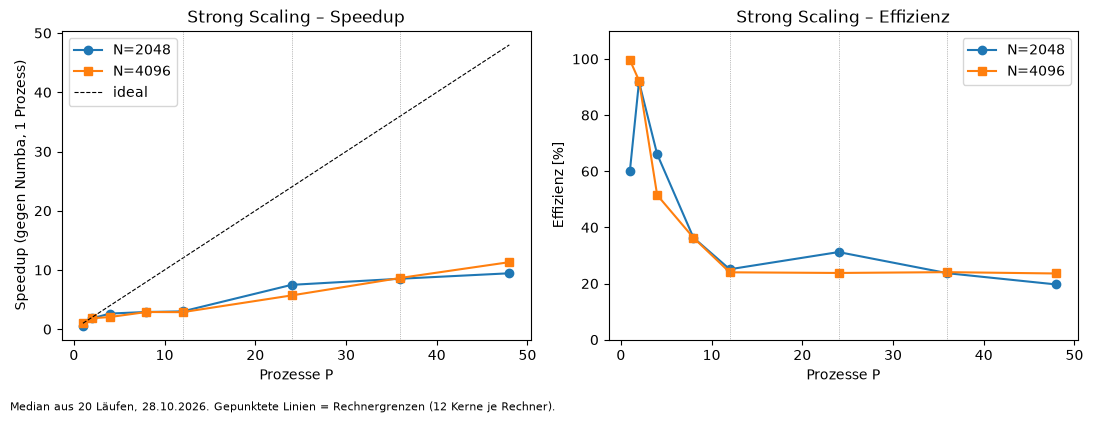

In [11]:
import matplotlib.pyplot as plt
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
Ps = np.array([1, 2, 4, 8, 12, 24, 36, 48])
for N, mk in ((2048, 'o'), (4096, 's')):
    t = np.array([np.median(d['zeit_s'][(d['N'] == N) & (d['P'] == P)]) for P in Ps])
    s = base[N] / t
    a1.plot(Ps, s, mk + '-', label=f'N={N}')
    a2.plot(Ps, 100 * s / Ps, mk + '-', label=f'N={N}')
a1.plot(Ps, Ps, 'k--', lw=0.8, label='ideal')
for x in (12, 24, 36):
    a1.axvline(x, color='grey', lw=0.5, ls=':'); a2.axvline(x, color='grey', lw=0.5, ls=':')
a1.set(xlabel='Prozesse P', ylabel='Speedup (gegen Numba, 1 Prozess)', title='Strong Scaling – Speedup')
a2.set(xlabel='Prozesse P', ylabel='Effizienz [%]', title='Strong Scaling – Effizienz', ylim=(0, 110))
a1.legend(); a2.legend()
fig.text(0.01, 0.01, 'Median aus 20 Läufen, 28.10.2026. Gepunktete Linien = Rechnergrenzen (12 Kerne je Rechner).', fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig('/home/itmvs/waerme/results/a_strong_baseline_2026-10-28.png', dpi=150)
plt.show()

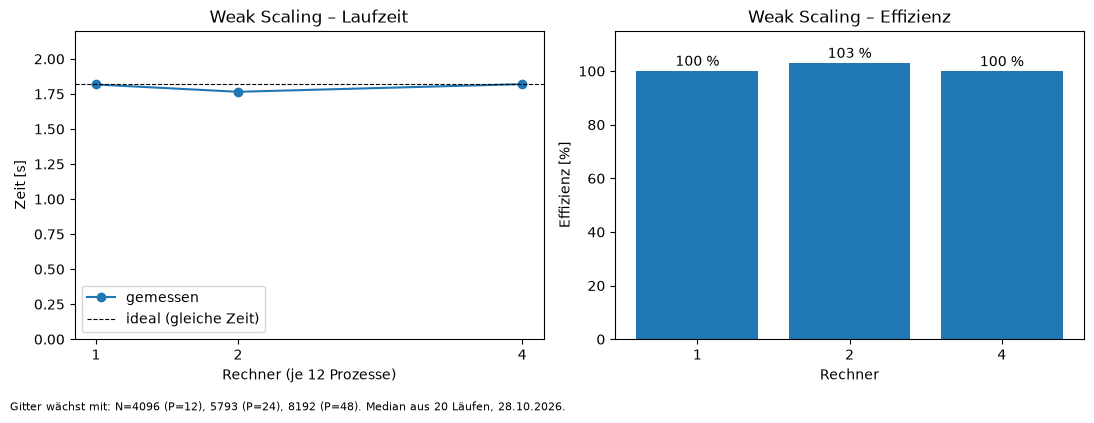

[1.8174 1.7652 1.82  ] [100.  103.   99.9]


In [12]:
w = np.genfromtxt('/home/itmvs/waerme/results/a_weak_2026-10-28.csv', delimiter=',',
                  names=True, dtype=None, encoding='utf-8')
cfg = [(4096, 12), (5793, 24), (8192, 48)]
med = np.array([np.median(w['zeit_s'][(w['N'] == N) & (w['P'] == P)]) for N, P in cfg])
eff = 100 * med[0] / med
rechner = [1, 2, 4]
fig, (b1, b2) = plt.subplots(1, 2, figsize=(11, 4.2))
b1.plot(rechner, med, 'o-', label='gemessen')
b1.axhline(med[0], color='k', ls='--', lw=0.8, label='ideal (gleiche Zeit)')
b1.set(xlabel='Rechner (je 12 Prozesse)', ylabel='Zeit [s]', title='Weak Scaling – Laufzeit',
       xticks=rechner, ylim=(0, 2.2))
b2.bar([str(r) for r in rechner], eff)
for i, e in enumerate(eff):
    b2.text(i, e + 2, f'{e:.0f} %', ha='center')
b2.set(xlabel='Rechner', ylabel='Effizienz [%]', title='Weak Scaling – Effizienz', ylim=(0, 115))
b1.legend()
fig.text(0.01, 0.01, 'Gitter wächst mit: N=4096 (P=12), 5793 (P=24), 8192 (P=48). Median aus 20 Läufen, 28.10.2026.', fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig('/home/itmvs/waerme/results/a_weak_2026-10-28.png', dpi=150)
plt.show()
print(np.round(med, 4), np.round(eff, 1))

N     P  Median[s]   95%-KI[s]            Mio.Upd/s  Komm%  Speedup
  256  1    0.0134     0.0133-   0.0134        981    5.5    1.00
  256 12    0.0050     0.0049-   0.0051       2598   65.0    2.65
  256 48    0.0521     0.0509-   0.0536        252   97.4    0.26
  512  1    0.0535     0.0531-   0.0537        980    1.7    1.00
  512 12    0.0135     0.0134-   0.0136       3894   51.5    3.97
  512 48    0.0664     0.0655-   0.0682        789   96.0    0.80
 1024  1    0.2230     0.2222-   0.2240        940    0.5    1.00
 1024 12    0.0320     0.0319-   0.0325       6555   25.7    6.97
 1024 48    0.0842     0.0811-   0.0893       2490   91.4    2.65
 2048  1    2.2131     2.2074-   2.2155        379    0.2    1.00
 2048 12    0.4416     0.4406-   0.4426       1899    4.1    5.01
 2048 48    0.1385     0.1356-   0.1518       6056   79.8   15.98
 4096  1    5.1879     5.1859-   5.1898        647    0.1    1.00
 4096 12    1.7864     1.7691-   1.8593       1878    4.3    2.90
 4096 48

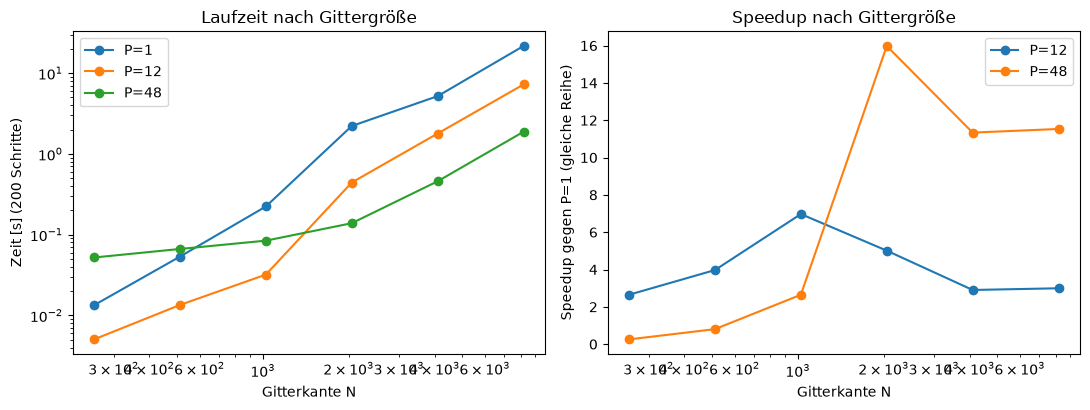

In [1]:
import numpy as np, matplotlib.pyplot as plt
d = np.genfromtxt('/home/itmvs/waerme/results/e1_groesse_2026-11-01.csv', delimiter=',', names=True, dtype=None, encoding='utf-8')

def ki(w):                         # 95-%-Konfidenzintervall des Medians (Hoefler & Belli 2015)
    w = np.sort(w); n = len(w)
    lo = int(np.floor((n - 1.96*np.sqrt(n))/2)); hi = int(np.ceil(1 + (n + 1.96*np.sqrt(n))/2))
    return w[lo-1], w[hi-1]

Ns = sorted(set(d['N'])); Ps = [1, 12, 48]; med = {}
print("N     P  Median[s]   95%-KI[s]            Mio.Upd/s  Komm%  Speedup")
for N in Ns:
    for P in Ps:
        m = (d['N'] == N) & (d['P'] == P)
        t = d['zeit_s'][m]; c = d['komm_max_s'][m]
        tm = np.median(t); med[(N, P)] = tm; lo, hi = ki(t)
        print(f"{N:5d} {P:2d} {tm:9.4f}  {lo:9.4f}-{hi:9.4f}  {N*N*200/tm/1e6:9.0f}  {100*np.median(c)/tm:5.1f}  {med[(N,1)]/tm:6.2f}")
print("Summen je N gleich:", all(np.ptp(d['summe'][d['N'] == N]) / abs(d['summe'][d['N'] == N][0]) < 1e-9 for N in Ns))

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
for P in Ps: a.loglog(Ns, [med[(N, P)] for N in Ns], 'o-', label=f'P={P}')
a.set(xlabel='Gitterkante N', ylabel='Zeit [s] (200 Schritte)', title='Laufzeit nach Gittergröße'); a.legend()
for P in (12, 48): b.semilogx(Ns, [med[(N, 1)] / med[(N, P)] for N in Ns], 'o-', label=f'P={P}')
b.set(xlabel='Gitterkante N', ylabel='Speedup gegen P=1 (gleiche Reihe)', title='Speedup nach Gittergröße'); b.legend()
fig.tight_layout(); fig.savefig('/home/itmvs/waerme/results/e1_groesse_2026-11-01.png', dpi=150); plt.show()

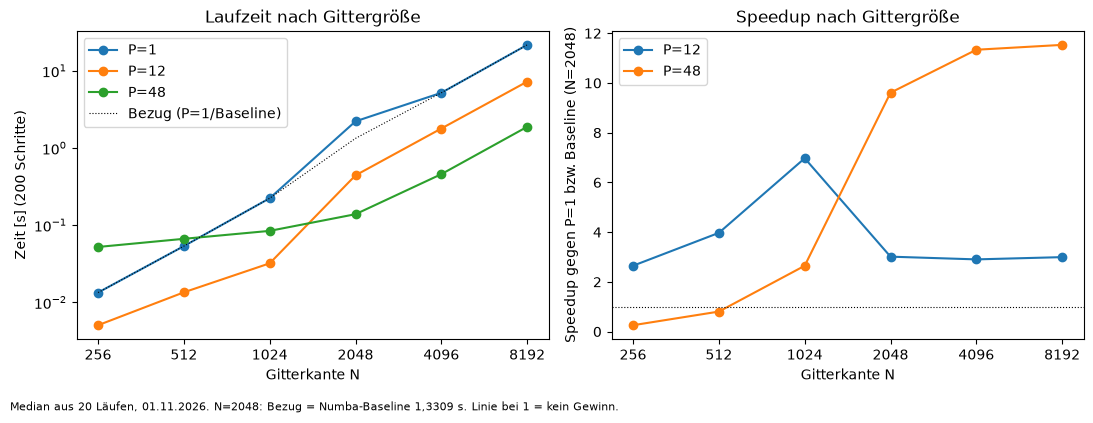

In [2]:
ref = {N: med[(N, 1)] for N in Ns}; ref[2048] = 1.3309          # N=2048: Numba-Baseline statt P=1 im langsamen Zustand
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
for P in Ps: a.loglog(Ns, [med[(N, P)] for N in Ns], 'o-', label=f'P={P}')
a.loglog(Ns, [ref[N] for N in Ns], 'k:', lw=0.8, label='Bezug (P=1/Baseline)')
for P in (12, 48): b.semilogx(Ns, [ref[N] / med[(N, P)] for N in Ns], 'o-', label=f'P={P}')
b.axhline(1, color='k', ls=':', lw=0.8)
for ax in (a, b): ax.minorticks_off(); ax.set_xticks(Ns); ax.set_xticklabels([str(n) for n in Ns]); ax.set_xlabel('Gitterkante N')
a.set(ylabel='Zeit [s] (200 Schritte)', title='Laufzeit nach Gittergröße'); a.legend()
b.set(ylabel='Speedup gegen P=1 bzw. Baseline (N=2048)', title='Speedup nach Gittergröße'); b.legend()
fig.text(0.01, 0.01, 'Median aus 20 Läufen, 01.11.2026. N=2048: Bezug = Numba-Baseline 1,3309 s. Linie bei 1 = kein Gewinn.', fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig('/home/itmvs/waerme/results/e1_groesse_2026-11-01.png', dpi=150); plt.show()

N     P  slot[s]  95%-KI[s]          node[s]  95%-KI[s]          slot/node  Komm%slot  Komm%node
 2048  4   0.5048  0.4973- 0.5135   0.3850  0.3747- 0.3939     1.31      5.3       30.2
 2048  8   0.4702  0.4576- 0.4750   0.2817  0.2759- 0.2860     1.67     11.7       47.1
 2048 12   0.4419  0.4410- 0.4431   0.2624  0.2575- 0.2674     1.68      4.1       60.2
 2048 24   0.1751  0.1736- 0.1820   0.3575  0.3565- 0.3593     0.49     63.4       85.4
 4096  4   2.5226  1.9956- 2.5652   2.3949  2.3897- 2.4087     1.05     32.1       44.6
 4096  8   1.7896  1.7799- 1.7986   0.9364  0.9322- 0.9452     1.91      5.6       25.3
 4096 12   1.8031  1.7878- 1.8262   0.7892  0.7788- 0.8037     2.28      4.2       35.3
 4096 24   0.9088  0.9000- 0.9208   0.7235  0.7034- 0.7486     1.26     42.5       64.1
Summen je N gleich: True


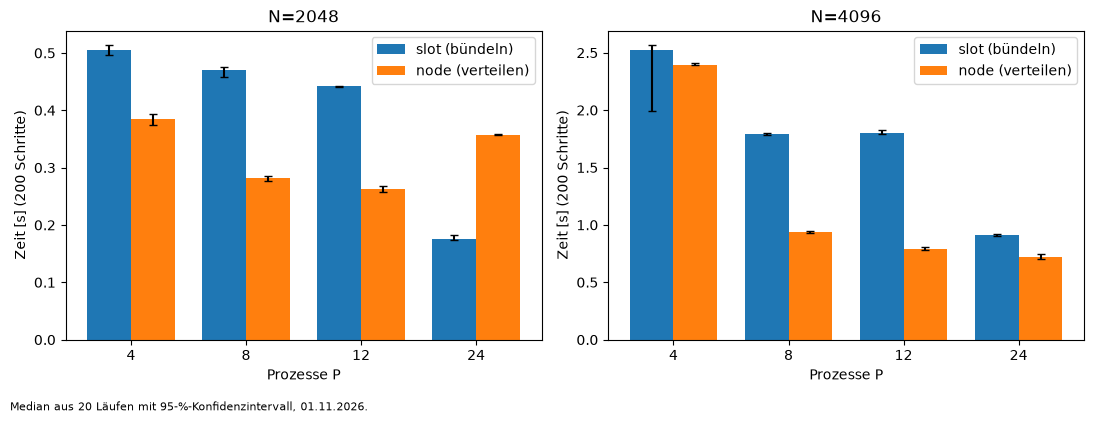

In [3]:
def ki(w):                         # 95-%-KI des Medians (Hoefler & Belli 2015)
    w = np.sort(w); n = len(w)
    lo = int(np.floor((n - 1.96*np.sqrt(n))/2)); hi = int(np.ceil(1 + (n + 1.96*np.sqrt(n))/2))
    return w[lo-1], w[hi-1]
lade = lambda f: np.genfromtxt(f, delimiter=',', names=True, dtype=None, encoding='utf-8')
ds = lade('/home/itmvs/waerme/results/e2_slot_2026-11-01.csv'); dn = lade('/home/itmvs/waerme/results/e2_node_2026-11-01.csv')
Ns2 = [2048, 4096]; Ps2 = [4, 8, 12, 24]; res = {}
print("N     P  slot[s]  95%-KI[s]          node[s]  95%-KI[s]          slot/node  Komm%slot  Komm%node")
for N in Ns2:
    for P in Ps2:
        for name, d in (('slot', ds), ('node', dn)):
            m = (d['N'] == N) & (d['P'] == P); t = d['zeit_s'][m]; c = d['komm_max_s'][m]
            res[(N, P, name)] = (np.median(t), *ki(t), 100*np.median(c)/np.median(t))
        s = res[(N, P, 'slot')]; n = res[(N, P, 'node')]
        print(f"{N:5d} {P:2d}  {s[0]:7.4f} {s[1]:7.4f}-{s[2]:7.4f}  {n[0]:7.4f} {n[1]:7.4f}-{n[2]:7.4f}  {s[0]/n[0]:7.2f}   {s[3]:6.1f}     {n[3]:6.1f}")
print("Summen je N gleich:", all(np.ptp(np.concatenate([ds['summe'][ds['N'] == N], dn['summe'][dn['N'] == N]])) / abs(ds['summe'][ds['N'] == N][0]) < 1e-9 for N in Ns2))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2)); x = np.arange(len(Ps2)); w = 0.38
for ax, N in zip(axs, Ns2):
    for k, (name, lab) in enumerate((('slot', 'slot (bündeln)'), ('node', 'node (verteilen)'))):
        r = [res[(N, P, name)] for P in Ps2]
        ax.bar(x + (k - 0.5)*w, [q[0] for q in r], w, label=lab, yerr=np.array([[q[0]-q[1], q[2]-q[0]] for q in r]).T, capsize=3)
    ax.set_xticks(x); ax.set_xticklabels(Ps2); ax.set(xlabel='Prozesse P', ylabel='Zeit [s] (200 Schritte)', title=f'N={N}'); ax.legend()
fig.text(0.01, 0.01, 'Median aus 20 Läufen mit 95-%-Konfidenzintervall, 01.11.2026.', fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig('/home/itmvs/waerme/results/e2_map_2026-11-01.png', dpi=150); plt.show()

Modus    Größe[B]  Median[µs]    95%-KI[µs]             MB/s
intra           8        1.80         1.79-      1.82         4.4
intra          64        1.83         1.81-      1.83        35.0
intra         512        2.37         2.36-      2.38       215.8
intra        4096        5.73         5.72-      5.74       715.2
intra       32768       10.00         9.97-     10.17      3276.4
intra      262144       46.81        46.69-     47.26      5599.6
intra     1048576      152.32       152.00-    152.91      6884.2
intra     4194304      522.94       522.13-    523.76      8020.6
intra    16777216     2191.64      2181.61-   2225.95      7655.1
  -> intra: Latenz α ≈ 1.80 µs (bei 8 B), Bandbreite β ≈ 7689 MB/s (Fit ab 256 KiB)
inter           8       53.10        53.02-     53.26         0.2
inter          64       54.69        54.66-     54.76         1.2
inter         512       66.66        66.62-     66.78         7.7
inter        4096      123.39       123.22-    123.52        33

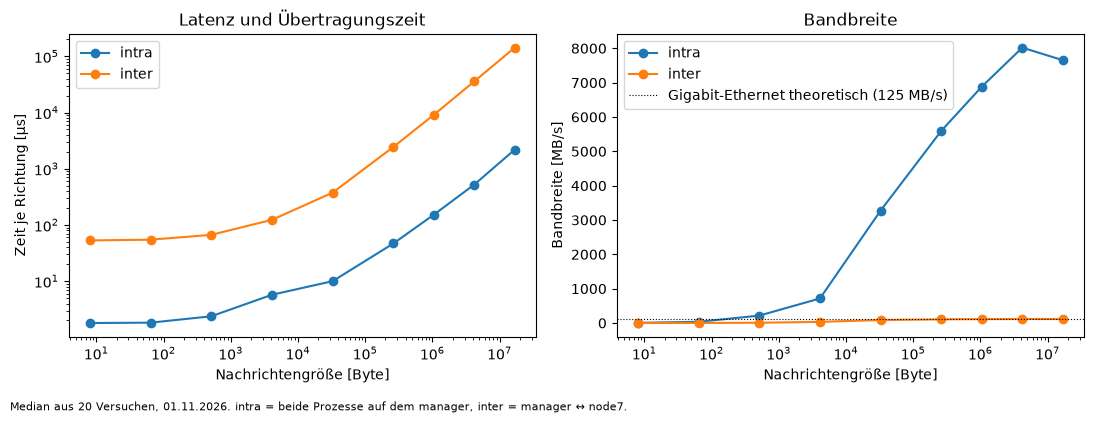

In [4]:
def ki(w):
    w = np.sort(w); n = len(w)
    lo = int(np.floor((n - 1.96*np.sqrt(n))/2)); hi = int(np.ceil(1 + (n + 1.96*np.sqrt(n))/2))
    return w[lo-1], w[hi-1]
lade = lambda f: np.genfromtxt(f, delimiter=',', names=True, dtype=None, encoding='utf-8')
e3 = lade('/home/itmvs/waerme/results/e3_pingpong_2026-11-01.csv'); daten = {}
print("Modus    Größe[B]  Median[µs]    95%-KI[µs]             MB/s")
for M in ('intra', 'inter'):
    ns, ts = [], []
    for n in sorted(set(e3['groesse_byte'][e3['modus'] == M])):
        w = e3['zeit_einfach_s'][(e3['modus'] == M) & (e3['groesse_byte'] == n)]
        tm = np.median(w); lo, hi = ki(w); ns.append(n); ts.append(tm)
        print(f"{M:5s} {n:11d} {tm*1e6:11.2f}   {lo*1e6:10.2f}-{hi*1e6:10.2f}   {n/tm/1e6:9.1f}")
    ns = np.array(ns, float); ts = np.array(ts); daten[M] = (ns, ts)
    g = ns >= 262144; sl, ic = np.polyfit(ns[g], ts[g], 1)
    print(f"  -> {M}: Latenz α ≈ {ts[0]*1e6:.2f} µs (bei 8 B), Bandbreite β ≈ {1/sl/1e6:.0f} MB/s (Fit ab 256 KiB)")
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2))
for M, (ns, ts) in daten.items():
    a.loglog(ns, ts*1e6, 'o-', label=M); b.semilogx(ns, ns/ts/1e6, 'o-', label=M)
b.axhline(125, color='k', ls=':', lw=0.8, label='Gigabit-Ethernet theoretisch (125 MB/s)')
a.set(xlabel='Nachrichtengröße [Byte]', ylabel='Zeit je Richtung [µs]', title='Latenz und Übertragungszeit'); a.legend()
b.set(xlabel='Nachrichtengröße [Byte]', ylabel='Bandbreite [MB/s]', title='Bandbreite'); b.legend()
fig.text(0.01, 0.01, 'Median aus 20 Versuchen, 01.11.2026. intra = beide Prozesse auf dem manager, inter = manager ↔ node7.', fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig('/home/itmvs/waerme/results/e3_pingpong_2026-11-01.png', dpi=150); plt.show()

N     P   slot[s]  node[s]  ppr[s]   (95%-KI)               best
 2048  2   0.7256   0.6902       -    node
 2048  4   0.5048   0.3850       -    node
 2048  8   0.4702   0.2817   0.2711 (0.2661-0.2741)  ppr
 2048 12   0.4419   0.2624   0.2106 (0.2086-0.2151)  ppr
 2048 24   0.1751   0.3575   0.1601 (0.1582-0.1628)  ppr
 2048 36   0.1554   0.5310   0.1460 (0.1412-0.1548)  ppr
 4096  2   2.7938   2.7927       -    node
 4096  4   2.5226   2.3949       -    node
 4096  8   1.7896   0.9364   0.8855 (0.8784-0.9043)  ppr
 4096 12   1.8031   0.7892   0.7151 (0.6974-0.7374)  ppr
 4096 24   0.9088   0.7235   0.5160 (0.5080-0.5206)  ppr
 4096 36   0.5987   1.0537   0.4654 (0.4625-0.4691)  ppr


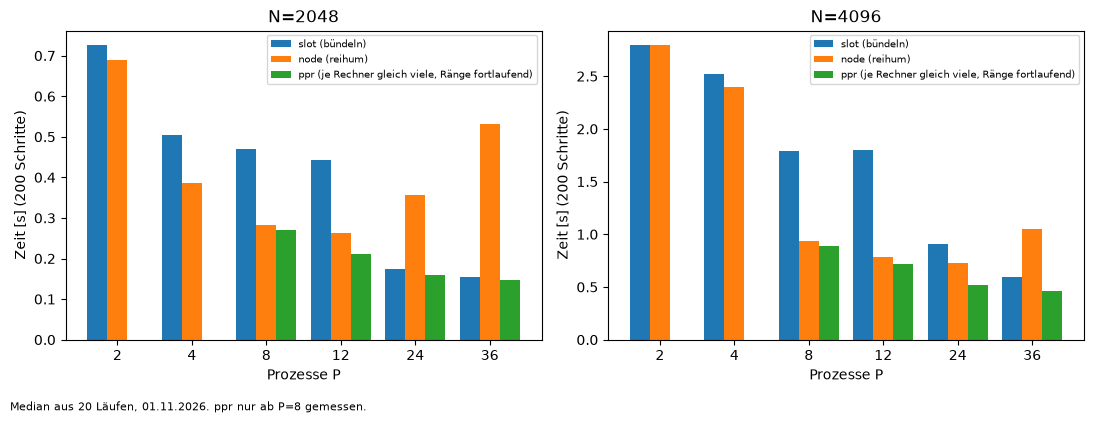

In [5]:
ds = lade('/home/itmvs/waerme/results/e2_slot_2026-11-01.csv'); dn = lade('/home/itmvs/waerme/results/e2_node_2026-11-01.csv')
bs = lade('/home/itmvs/waerme/results/e2b_slot_2026-11-01.csv'); bn = lade('/home/itmvs/waerme/results/e2b_node_2026-11-01.csv')
pp = lade('/home/itmvs/waerme/results/e2d_ppr_2026-11-01.csv')
def med_ki(d, N, P):
    t = d['zeit_s'][(d['N'] == N) & (d['P'] == P)]; lo, hi = ki(t); return np.median(t), lo, hi
print("N     P   slot[s]  node[s]  ppr[s]   (95%-KI)               best")
tab = {}
for N in (2048, 4096):
    for P in (2, 4, 8, 12, 24, 36):
        s = med_ki(ds if P in (4, 8, 12, 24) else bs, N, P); n = med_ki(dn if P in (4, 8, 12, 24) else bn, N, P)
        p = med_ki(pp, N, P) if P >= 8 else None
        tab[(N, P)] = (s, n, p)
        cand = {'slot': s[0], 'node': n[0]}; 
        if p: cand['ppr'] = p[0]
        best = min(cand, key=cand.get)
        ptxt = f"{p[0]:7.4f} ({p[1]:.4f}-{p[2]:.4f})" if p else "     -  "
        print(f"{N:5d} {P:2d}  {s[0]:7.4f}  {n[0]:7.4f}  {ptxt}  {best}")
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2)); Ps = [2, 4, 8, 12, 24, 36]; x = np.arange(len(Ps)); w = 0.27
for ax, N in zip(axs, (2048, 4096)):
    ax.bar(x - w, [tab[(N, P)][0][0] for P in Ps], w, label='slot (bündeln)')
    ax.bar(x, [tab[(N, P)][1][0] for P in Ps], w, label='node (reihum)')
    ax.bar(x + w, [tab[(N, P)][2][0] if tab[(N, P)][2] else 0 for P in Ps], w, label='ppr (je Rechner gleich viele, Ränge fortlaufend)')
    ax.set_xticks(x); ax.set_xticklabels(Ps); ax.set(xlabel='Prozesse P', ylabel='Zeit [s] (200 Schritte)', title=f'N={N}'); ax.legend(fontsize=7)
fig.text(0.01, 0.01, 'Median aus 20 Läufen, 01.11.2026. ppr nur ab P=8 gemessen.', fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig('/home/itmvs/waerme/results/e2d_vergleich_2026-11-01.png', dpi=150); plt.show()

In [6]:
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

R = os.path.expanduser("~/waerme/results/")
T1 = 21.6662   # Median P=1, N=8192 aus E1 (Referenz)

def lade_e2c(f):
    d = pd.read_csv(f)
    return d

def med_ci(w):
    w = np.sort(np.asarray(w, dtype=float))
    n = len(w)   # n=20 -> Rang 5 und 16 (1-basiert)
    lo = w[int(np.floor((n - 1.96*np.sqrt(n))/2)) - 1]
    hi = w[int(np.ceil(1 + (n + 1.96*np.sqrt(n))/2)) - 1]
    return np.median(w), lo, hi

teile = {
  "slot": [R+"e2c_slot_2026-11-01.csv"],
  "node": [R+"e2c_node_2026-11-01.csv"],
  "ppr":  sorted(glob.glob(R+"e2c_ppr_P*_2026-11-01.csv")),
}
Ps = [4, 8, 12, 24]
erg = {}
for m, files in teile.items():
    d = pd.concat([lade_e2c(f) for f in files])
    for P in Ps:
        w = d[d["P"] == P]["zeit_s"]
        erg[(m, P)] = med_ci(w) + (len(w),)

zeilen = []
for P in Ps:
    for m in ["slot", "node", "ppr"]:
        med, lo, hi, n = erg[(m, P)]
        S = T1/med
        zeilen.append([P, m, n, round(med,4), round(lo,4), round(hi,4), round(S,2), round(100*S/P,1)])
tab = pd.DataFrame(zeilen, columns=["P","Mapping","n","Median_s","CI_lo","CI_hi","Speedup","Effizienz_%"])
print(tab.to_string(index=False))

fig, ax = plt.subplots(figsize=(8,4.5))
breite = 0.26
farben = {"slot":"#1f77b4","node":"#ff7f0e","ppr":"#2ca02c"}
for i, m in enumerate(["slot","node","ppr"]):
    med = np.array([erg[(m,P)][0] for P in Ps])
    lo  = np.array([erg[(m,P)][1] for P in Ps])
    hi  = np.array([erg[(m,P)][2] for P in Ps])
    ax.bar(np.arange(len(Ps)) + (i-1)*breite, med, breite,
           yerr=[med-lo, hi-med], capsize=3, label=m, color=farben[m])
ax.set_xticks(range(len(Ps))); ax.set_xticklabels([f"P={P}" for P in Ps])
ax.set_ylabel("Median Laufzeit (s), 200 Schritte")
ax.set_title("E2c: N=8192, Prozessverteilung (95 %-CI, n=20)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(R+"e2c_vergleich_2026-11-01.png", dpi=150)
plt.show()

ModuleNotFoundError: No module named 'pandas'

  P Mapping   n  Median_s    CI_lo    CI_hi  Speedup  Eff_%
  4 slot   20    8.0718   7.9786   8.1281     2.68   67.1
  4 node   20    6.1661   6.1427   6.2287     3.51   87.8
  4 ppr    20    6.1691   6.1493   6.2248     3.51   87.8
  8 slot   20    7.2597   7.0720   7.3184     2.98   37.3
  8 node   20    3.5151   3.4887   3.5602     6.16   77.0
  8 ppr    20    3.3648   3.3479   3.3956     6.44   80.5
 12 slot   20    7.3506   7.2966   7.4821     2.95   24.6
 12 node   20    3.3322   2.9488   5.1119     6.50   54.2
 12 ppr    20    2.5526   2.4995   3.2855     8.49   70.7
 24 slot   20    3.6896   3.6752   3.7081     5.87   24.5
 24 node   20    2.6041   2.5677   7.9905     8.32   34.7
 24 ppr    20    1.9860   1.9600   2.0573    10.91   45.5


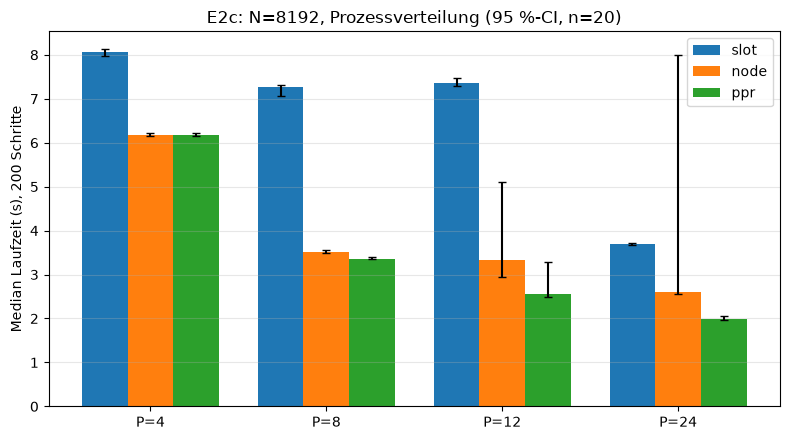

In [7]:
import os, glob, csv
import numpy as np
import matplotlib.pyplot as plt

R = os.path.expanduser("~/waerme/results/")
T1 = 21.6662   # Median P=1, N=8192 aus E1 (Referenz)

def lade_e2c(files):
    # liest CSV-Dateien, gibt Liste von (P, zeit_s) zurück
    out = []
    for f in files:
        with open(f) as fh:
            for z in csv.DictReader(fh):
                out.append((int(z["P"]), float(z["zeit_s"])))
    return out

def med_ci(w):
    w = np.sort(np.asarray(w, dtype=float))
    n = len(w)   # n=20 -> Rang 5 und 16 (1-basiert)
    lo = w[int(np.floor((n - 1.96*np.sqrt(n))/2)) - 1]
    hi = w[int(np.ceil(1 + (n + 1.96*np.sqrt(n))/2)) - 1]
    return np.median(w), lo, hi

teile = {
  "slot": [R+"e2c_slot_2026-11-01.csv"],
  "node": [R+"e2c_node_2026-11-01.csv"],
  "ppr":  sorted(glob.glob(R+"e2c_ppr_P*_2026-11-01.csv")),
}
Ps = [4, 8, 12, 24]
erg = {}
for m, files in teile.items():
    daten = lade_e2c(files)
    for P in Ps:
        w = [t for (p, t) in daten if p == P]
        erg[(m, P)] = med_ci(w) + (len(w),)

print(f"{'P':>3} {'Mapping':<5} {'n':>3} {'Median_s':>9} {'CI_lo':>8} {'CI_hi':>8} {'Speedup':>8} {'Eff_%':>6}")
for P in Ps:
    for m in ["slot", "node", "ppr"]:
        med, lo, hi, n = erg[(m, P)]
        S = T1/med
        print(f"{P:>3} {m:<5} {n:>3} {med:>9.4f} {lo:>8.4f} {hi:>8.4f} {S:>8.2f} {100*S/P:>6.1f}")

fig, ax = plt.subplots(figsize=(8,4.5))
breite = 0.26
farben = {"slot":"#1f77b4","node":"#ff7f0e","ppr":"#2ca02c"}
for i, m in enumerate(["slot","node","ppr"]):
    med = np.array([erg[(m,P)][0] for P in Ps])
    lo  = np.array([erg[(m,P)][1] for P in Ps])
    hi  = np.array([erg[(m,P)][2] for P in Ps])
    ax.bar(np.arange(len(Ps)) + (i-1)*breite, med, breite,
           yerr=[med-lo, hi-med], capsize=3, label=m, color=farben[m])
ax.set_xticks(range(len(Ps))); ax.set_xticklabels([f"P={P}" for P in Ps])
ax.set_ylabel("Median Laufzeit (s), 200 Schritte")
ax.set_title("E2c: N=8192, Prozessverteilung (95 %-CI, n=20)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(R+"e2c_vergleich_2026-11-01.png", dpi=150)
plt.show()


Modus          P   n  Summe_GB/s   CI_lo   CI_hi  je Proz.
ein_rechner    1  20       13.27   13.21   13.31     13.27
ein_rechner    2  20       23.20   23.12   23.25     11.60
ein_rechner    4  20       39.71   39.58   39.84      9.93
ein_rechner    6  20       46.05   45.95   46.21      7.67
ein_rechner    8  20       48.04   47.87   48.18      6.00
ein_rechner   12  20       46.84   46.70   46.97      3.90
vier_rechner   4  20       52.68   52.46   53.02     13.17
vier_rechner   8  20       92.04   91.90   92.29     11.51
vier_rechner  12  20      126.59  126.12  126.91     10.55
vier_rechner  24  20      181.88  181.38  181.97      7.58
vier_rechner  48  20      185.30  184.77  185.77      3.86


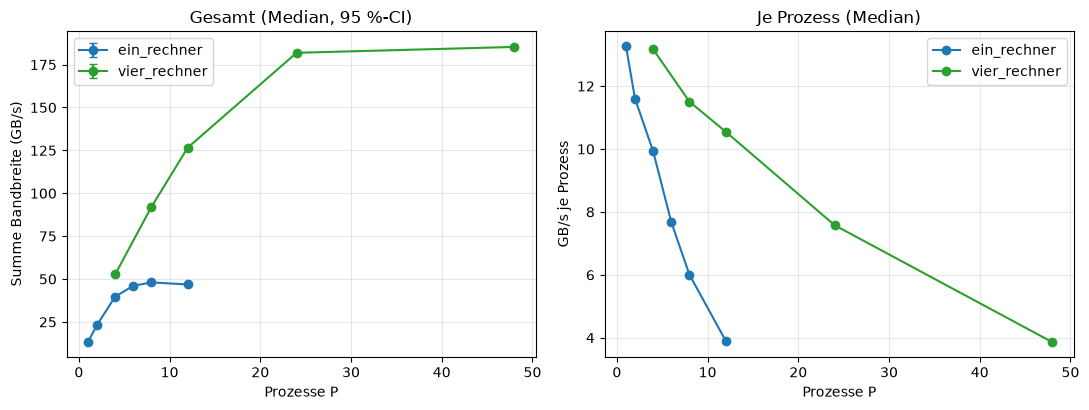

In [8]:
import os, csv
import numpy as np
import matplotlib.pyplot as plt

R = os.path.expanduser("~/waerme/results/")
daten = {}
with open(R+"e10_bandbreite_2026-11-01.csv") as fh:
    for z in csv.DictReader(fh):
        k = (z["modus"], int(z["P"]))
        daten.setdefault(k, {"sum": [], "pro": []})
        daten[k]["sum"].append(float(z["gb_summe"]))
        daten[k]["pro"].append(float(z["gb_pro_prozess"]))

def med_ci(w):
    w = np.sort(np.asarray(w, dtype=float)); n = len(w)
    lo = w[int(np.floor((n - 1.96*np.sqrt(n))/2)) - 1]
    hi = w[int(np.ceil(1 + (n + 1.96*np.sqrt(n))/2)) - 1]
    return np.median(w), lo, hi

modi = ["ein_rechner", "vier_rechner"]
erg = {k: (med_ci(v["sum"]), med_ci(v["pro"]), len(v["sum"])) for k, v in daten.items()}

print(f"{'Modus':<13}{'P':>3}{'n':>4}{'Summe_GB/s':>12}{'CI_lo':>8}{'CI_hi':>8}{'je Proz.':>10}")
for m in modi:
    for P in sorted(p for (mm, p) in erg if mm == m):
        (s, sl, sh), (pr, _, _), n = erg[(m, P)]
        print(f"{m:<13}{P:>3}{n:>4}{s:>12.2f}{sl:>8.2f}{sh:>8.2f}{pr:>10.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
farben = {"ein_rechner": "#1f77b4", "vier_rechner": "#2ca02c"}
for m in modi:
    Ps = sorted(p for (mm, p) in erg if mm == m)
    s  = np.array([erg[(m, P)][0][0] for P in Ps])
    sl = np.array([erg[(m, P)][0][1] for P in Ps])
    sh = np.array([erg[(m, P)][0][2] for P in Ps])
    pr = np.array([erg[(m, P)][1][0] for P in Ps])
    ax[0].errorbar(Ps, s, yerr=[s-sl, sh-s], marker="o", capsize=3, label=m, color=farben[m])
    ax[1].plot(Ps, pr, marker="o", label=m, color=farben[m])
ax[0].set_xlabel("Prozesse P"); ax[0].set_ylabel("Summe Bandbreite (GB/s)")
ax[0].set_title("Gesamt (Median, 95 %-CI)")
ax[1].set_xlabel("Prozesse P"); ax[1].set_ylabel("GB/s je Prozess")
ax[1].set_title("Je Prozess (Median)")
for a in ax: a.grid(alpha=0.3); a.legend()
plt.tight_layout()
plt.savefig(R+"e10_bandbreite_2026-11-01.png", dpi=150)
plt.show()

    N   P Raster Streifen_s  Bloecke_s    B/S CI-ueberlapp  Komm%_S  Komm%_B
 2048  12    4x3     0.2106     0.2044  0.971         nein     52.7     57.3   n=20/20
 2048  24    6x4     0.1601     0.1401  0.875         nein     67.5     69.0   n=20/20
 2048  48    8x6     0.1385     0.1180  0.852         nein     79.8     81.5   n=20/20
 4096  12    4x3     0.7151     0.7022  0.982           ja     30.0     27.8   n=20/20
 4096  24    6x4     0.5160     0.5894  1.142         nein     42.2     35.8   n=20/20
 4096  48    8x6     0.4576     0.4915  1.074         nein     50.6     57.1   n=20/20
 8192  12    4x3     2.5526     2.6468  1.037           ja     19.5     23.4   n=20/20
 8192  24    6x4     1.9860     2.1558  1.085         nein     37.6     28.4   n=20/20
 8192  48    8x6     1.8788     1.8775  0.999           ja     50.8     47.8   n=20/20


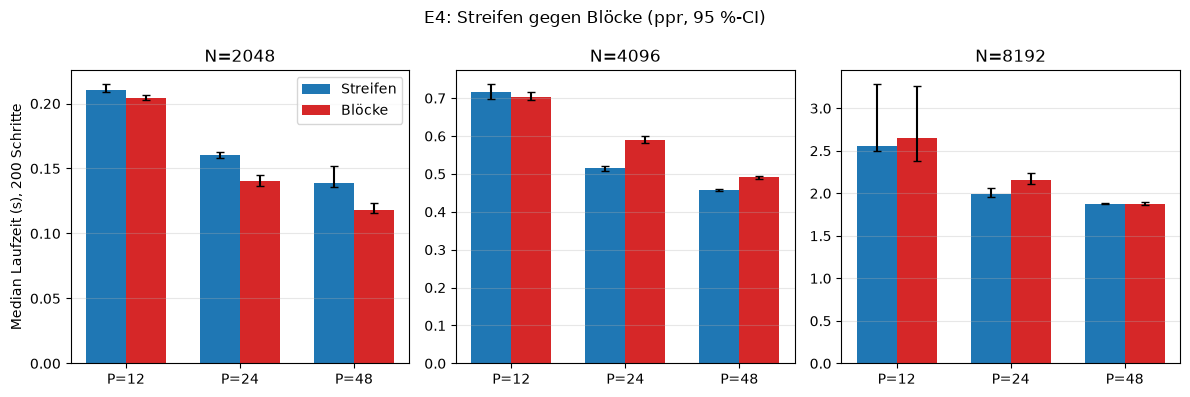

In [10]:
import os, csv, glob
import numpy as np
import matplotlib.pyplot as plt

R = os.path.expanduser("~/waerme/results/")

def lade(files):
    d = {}
    for f in files:
        with open(f) as fh:
            for z in csv.DictReader(fh):
                k = (int(z["P"]), int(z["N"]))
                d.setdefault(k, {"t": [], "c": []})
                d[k]["t"].append(float(z["zeit_s"]))
                d[k]["c"].append(float(z["komm_max_s"]))
    return d

def med_ci(w):
    w = np.sort(np.asarray(w, dtype=float)); n = len(w)
    lo = w[int(np.floor((n - 1.96*np.sqrt(n))/2)) - 1]
    hi = w[int(np.ceil(1 + (n + 1.96*np.sqrt(n))/2)) - 1]
    return np.median(w), lo, hi

# Blöcke (neu) und Streifen (E2d, E2c, E1; alle ppr bzw. gleichwertig)
bl = lade(sorted(glob.glob(R+"e4_bloecke_P*_2026-11-01.csv")))
st = lade([R+"e2d_ppr_2026-11-01.csv"] + sorted(glob.glob(R+"e2c_ppr_P*_2026-11-01.csv")))
st48 = lade([R+"e1_groesse_2026-11-01.csv"])      # aus E1 nur P=48 (12 je Rechner = ppr)
for N_ in (2048, 4096, 8192):
    st[(48, N_)] = st48[(48, N_)]
    
Ns = [2048, 4096, 8192]; Ps = [12, 24, 48]
raster = {12: "4x3", 24: "6x4", 48: "8x6"}

print(f"{'N':>5} {'P':>3} {'Raster':>6} {'Streifen_s':>10} {'Bloecke_s':>10} {'B/S':>6} {'CI-ueberlapp':>12} {'Komm%_S':>8} {'Komm%_B':>8}")
erg = {}
for N in Ns:
    for P in Ps:
        s = st[(P, N)]; b = bl[(P, N)]
        ms, sl, sh = med_ci(s["t"]); mb, bl_, bh = med_ci(b["t"])
        ueber = "ja" if (bl_ <= sh and sl <= bh) else "nein"
        ks = 100*np.median(s["c"])/np.median(s["t"]); kb = 100*np.median(b["c"])/np.median(b["t"])
        erg[(N, P)] = (ms, sl, sh, mb, bl_, bh, len(s["t"]), len(b["t"]))
        print(f"{N:>5} {P:>3} {raster[P]:>6} {ms:>10.4f} {mb:>10.4f} {mb/ms:>6.3f} {ueber:>12} {ks:>8.1f} {kb:>8.1f}   n={len(s['t'])}/{len(b['t'])}")

fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=False)
for a, N in zip(ax, Ns):
    x = np.arange(len(Ps)); w = 0.35
    for off, idx, lab, col in [(-w/2, 0, "Streifen", "#1f77b4"), (w/2, 3, "Blöcke", "#d62728")]:
        med = np.array([erg[(N, P)][idx] for P in Ps])
        lo = np.array([erg[(N, P)][idx+1] for P in Ps]); hi = np.array([erg[(N, P)][idx+2] for P in Ps])
        a.bar(x+off, med, w, yerr=[med-lo, hi-med], capsize=3, label=lab, color=col)
    a.set_xticks(x); a.set_xticklabels([f"P={P}" for P in Ps]); a.set_title(f"N={N}")
    a.grid(axis="y", alpha=0.3)
ax[0].set_ylabel("Median Laufzeit (s), 200 Schritte"); ax[0].legend()
plt.suptitle("E4: Streifen gegen Blöcke (ppr, 95 %-CI)")
plt.tight_layout()
plt.savefig(R+"e4_streifen_bloecke_2026-11-01.png", dpi=150)
plt.show()

  P     N Streifen_s Ueberlapp_s    U/S CI-ueberlapp  Komm%_S  Komm%_U  n
 48   256     0.0521      0.0326  0.626         nein     97.4     94.7  20/20
 48   512     0.0664      0.0390  0.586         nein     96.0     91.1  20/20
 48  1024     0.0842      0.0495  0.588         nein     91.4     83.7  20/20
 48  2048     0.1385      0.0679  0.490         nein     79.8     57.6  20/20
 48  4096     0.4576      0.4502  0.984         nein     50.6     30.4  20/20
 48  8192     1.8788      1.8427  0.981         nein     50.8     24.2  20/20
 24  2048     0.1601      0.0799  0.499         nein     67.5     33.4  20/20
 24  4096     0.5160      0.4845  0.939         nein     42.2     16.6  20/20
 24  8192     1.9860      2.0230  1.019           ja     37.6     22.5  20/20
 12  2048     0.2106      0.1318  0.626         nein     52.7     21.0  20/20
 12  4096     0.7151      0.5932  0.830         nein     30.0      9.5  20/20
 12  8192     2.5526      3.2266  1.264           ja     19.5     35

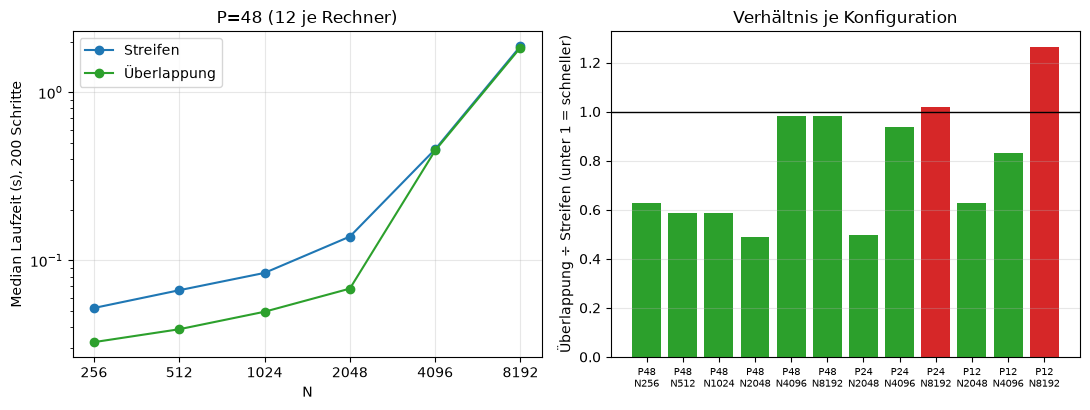

In [11]:
import os, csv, glob
import numpy as np
import matplotlib.pyplot as plt

R = os.path.expanduser("~/waerme/results/")

def lade(files, nur_P=None):
    d = {}
    for f in files:
        with open(f) as fh:
            for z in csv.DictReader(fh):
                P = int(z["P"])
                if nur_P is not None and P not in nur_P:
                    continue
                k = (P, int(z["N"]))
                d.setdefault(k, {"t": [], "c": []})
                d[k]["t"].append(float(z["zeit_s"]))
                d[k]["c"].append(float(z["komm_max_s"]))
    return d

def med_ci(w):
    w = np.sort(np.asarray(w, dtype=float)); n = len(w)
    lo = w[int(np.floor((n - 1.96*np.sqrt(n))/2)) - 1]
    hi = w[int(np.ceil(1 + (n + 1.96*np.sqrt(n))/2)) - 1]
    return np.median(w), lo, hi

ov = lade(sorted(glob.glob(R+"e5_overlap_P*_2026-11-01.csv")))
st = lade([R+"e2d_ppr_2026-11-01.csv"] + sorted(glob.glob(R+"e2c_ppr_P*_2026-11-01.csv")), nur_P=(12, 24))
st.update(lade([R+"e1_groesse_2026-11-01.csv"], nur_P=(48,)))   # aus E1 nur P=48

schluessel = sorted(ov.keys(), key=lambda k: (-k[0], k[1]))
print(f"{'P':>3} {'N':>5} {'Streifen_s':>10} {'Ueberlapp_s':>11} {'U/S':>6} {'CI-ueberlapp':>12} {'Komm%_S':>8} {'Komm%_U':>8}  n")
erg = {}
for (P, N) in schluessel:
    s = st[(P, N)]; o = ov[(P, N)]
    ms, sl, sh = med_ci(s["t"]); mo, ol, oh = med_ci(o["t"])
    ueber = "ja" if (ol <= sh and sl <= oh) else "nein"
    ks = 100*np.median(s["c"])/np.median(s["t"]); ko = 100*np.median(o["c"])/np.median(o["t"])
    erg[(P, N)] = (ms, sl, sh, mo, ol, oh)
    print(f"{P:>3} {N:>5} {ms:>10.4f} {mo:>11.4f} {mo/ms:>6.3f} {ueber:>12} {ks:>8.1f} {ko:>8.1f}  {len(s['t'])}/{len(o['t'])}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
N48 = [N for (P, N) in schluessel if P == 48]
for idx, lab, col in [(0, "Streifen", "#1f77b4"), (3, "Überlappung", "#2ca02c")]:
    ax[0].plot(N48, [erg[(48, N)][idx] for N in N48], marker="o", label=lab, color=col)
ax[0].set_xscale("log", base=2); ax[0].set_yscale("log")
ax[0].set_xticks(N48); ax[0].set_xticklabels([str(N) for N in N48])
ax[0].set_xlabel("N"); ax[0].set_ylabel("Median Laufzeit (s), 200 Schritte")
ax[0].set_title("P=48 (12 je Rechner)"); ax[0].legend(); ax[0].grid(alpha=0.3)
namen = [f"P{P}\nN{N}" for (P, N) in schluessel]
ver = [erg[k][3]/erg[k][0] for k in schluessel]
ax[1].bar(range(len(schluessel)), ver, color=["#2ca02c" if v < 1 else "#d62728" for v in ver])
ax[1].axhline(1, color="k", lw=1)
ax[1].set_xticks(range(len(schluessel))); ax[1].set_xticklabels(namen, fontsize=7)
ax[1].set_ylabel("Überlappung ÷ Streifen (unter 1 = schneller)")
ax[1].set_title("Verhältnis je Konfiguration"); ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(R+"e5_overlap_2026-11-01.png", dpi=150)
plt.show()

  P     N  Streifen NB_sofort Ueberlapp   NB/S   U/NB  NBvsS  UvsNB  n
 48   256    0.0521    0.0328    0.0326  0.630  0.994   nein     ja  20/20/20
 48   512    0.0664    0.0412    0.0390  0.619  0.947   nein     ja  20/20/20
 48  1024    0.0842    0.0552    0.0495  0.655  0.897   nein   nein  20/20/20
 48  2048    0.1385    0.0996    0.0679  0.719  0.682   nein   nein  20/20/20
 48  4096    0.4576    0.4482    0.4502  0.979  1.004   nein     ja  20/20/20
 48  8192    1.8788    1.8184    1.8427  0.968  1.013   nein   nein  20/20/20
 24  2048    0.1601    0.1111    0.0799  0.694  0.719   nein   nein  20/20/20
 24  4096    0.5160    0.4837    0.4845  0.937  1.002   nein     ja  20/20/20
 24  8192    1.9860    1.9219    2.0230  0.968  1.053     ja     ja  20/20/20
 12  2048    0.2106    0.1740    0.1318  0.826  0.758   nein   nein  20/20/20
 12  4096    0.7151    0.6261    0.5932  0.876  0.948   nein   nein  20/20/20
 12  8192    2.5526    3.2525    3.2266  1.274  0.992     ja     ja  20

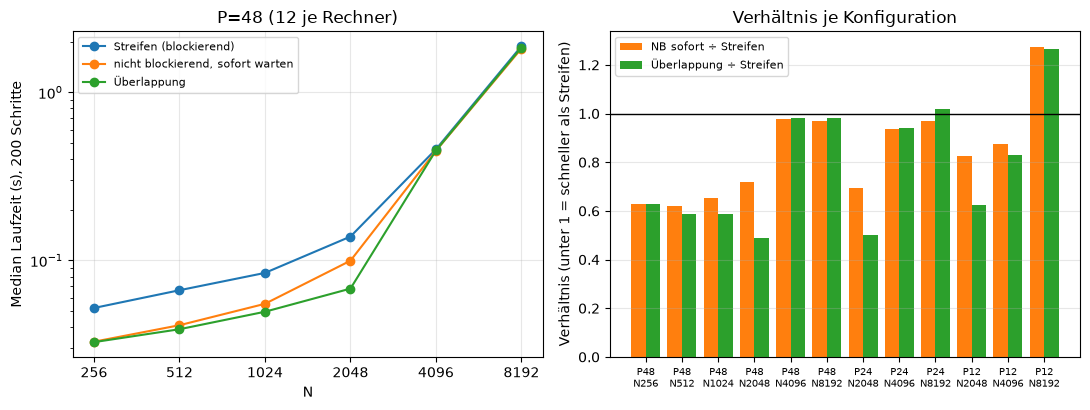

In [12]:
import os, csv, glob
import numpy as np
import matplotlib.pyplot as plt

R = os.path.expanduser("~/waerme/results/")

def lade(files, nur_P=None):
    d = {}
    for f in files:
        with open(f) as fh:
            for z in csv.DictReader(fh):
                P = int(z["P"])
                if nur_P is not None and P not in nur_P:
                    continue
                k = (P, int(z["N"]))
                d.setdefault(k, []).append(float(z["zeit_s"]))
    return d

def med_ci(w):
    w = np.sort(np.asarray(w, dtype=float)); n = len(w)
    lo = w[int(np.floor((n - 1.96*np.sqrt(n))/2)) - 1]
    hi = w[int(np.ceil(1 + (n + 1.96*np.sqrt(n))/2)) - 1]
    return np.median(w), lo, hi

st = lade([R+"e2d_ppr_2026-11-01.csv"] + sorted(glob.glob(R+"e2c_ppr_P*_2026-11-01.csv")), nur_P=(12, 24))
st.update(lade([R+"e1_groesse_2026-11-01.csv"], nur_P=(48,)))
ov = lade(sorted(glob.glob(R+"e5_overlap_P*_2026-11-01.csv")))
nb = lade(sorted(glob.glob(R+"e5b_nb_P*_2026-11-01.csv")))

def ueber(a, b):
    return "ja" if (a[1] <= b[2] and b[1] <= a[2]) else "nein"

schl = sorted(nb.keys(), key=lambda k: (-k[0], k[1]))
print(f"{'P':>3} {'N':>5} {'Streifen':>9} {'NB_sofort':>9} {'Ueberlapp':>9} {'NB/S':>6} {'U/NB':>6} {'NBvsS':>6} {'UvsNB':>6}  n")
erg = {}
for k in schl:
    s = med_ci(st[k]); b = med_ci(nb[k]); o = med_ci(ov[k])
    erg[k] = (s[0], b[0], o[0])
    print(f"{k[0]:>3} {k[1]:>5} {s[0]:>9.4f} {b[0]:>9.4f} {o[0]:>9.4f} {b[0]/s[0]:>6.3f} {o[0]/b[0]:>6.3f} {ueber(s,b):>6} {ueber(b,o):>6}  {len(st[k])}/{len(nb[k])}/{len(ov[k])}")
print("NBvsS / UvsNB: 'ja' = Konfidenzintervalle überlappen (Unterschied nicht belegt)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
N48 = [k[1] for k in schl if k[0] == 48]
for i, lab, col in [(0, "Streifen (blockierend)", "#1f77b4"), (1, "nicht blockierend, sofort warten", "#ff7f0e"), (2, "Überlappung", "#2ca02c")]:
    ax[0].plot(N48, [erg[(48, N)][i] for N in N48], marker="o", label=lab, color=col)
ax[0].set_xscale("log", base=2); ax[0].set_yscale("log")
ax[0].set_xticks(N48); ax[0].set_xticklabels([str(N) for N in N48])
ax[0].set_xlabel("N"); ax[0].set_ylabel("Median Laufzeit (s), 200 Schritte")
ax[0].set_title("P=48 (12 je Rechner)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
x = np.arange(len(schl)); w = 0.4
ax[1].bar(x - w/2, [erg[k][1]/erg[k][0] for k in schl], w, label="NB sofort ÷ Streifen", color="#ff7f0e")
ax[1].bar(x + w/2, [erg[k][2]/erg[k][0] for k in schl], w, label="Überlappung ÷ Streifen", color="#2ca02c")
ax[1].axhline(1, color="k", lw=1)
ax[1].set_xticks(x); ax[1].set_xticklabels([f"P{k[0]}\nN{k[1]}" for k in schl], fontsize=7)
ax[1].set_ylabel("Verhältnis (unter 1 = schneller als Streifen)")
ax[1].legend(fontsize=8); ax[1].grid(axis="y", alpha=0.3); ax[1].set_title("Verhältnis je Konfiguration")
plt.tight_layout()
plt.savefig(R+"e5b_vergleich_2026-11-01.png", dpi=150)
plt.show()

Teil 1: stationäre Lösung gegen analytische Reihe (r=0.2)
   N         h  Schritte  RMS_Fehler  Max_Fehler_Mitte  Verh.RMS Verh.Mitte Rechenzeit_s
  17   0.06250       907   1.413e-01         1.204e-01       nan        nan          0.0
  33   0.03125      3631   6.838e-02         3.074e-02      2.07       3.92          0.1
  65   0.01562     14525   3.365e-02         7.740e-03      2.03       3.97          1.0
 129   0.00781     58101   1.669e-02         1.955e-03      2.02       3.96         11.0
Erwartung bei Ordnung 2 im Ort: Verhältnis ≈ 4 pro Halbierung von h (Mitte); RMS kann wegen der Ecken abweichen.

Teil 2: Stabilität - größter Betrag |u| nach k Schritten (N=33)
     r           50          100          200          300
  0.20    1.000e+02    1.000e+02    1.000e+02    1.000e+02
  0.24    1.000e+02    1.000e+02    1.000e+02    1.000e+02
  0.25    1.000e+02    1.000e+02    1.000e+02    1.000e+02
  0.26    1.000e+02    1.000e+02    5.740e+02    6.724e+05
  0.30    3.158e+04    1

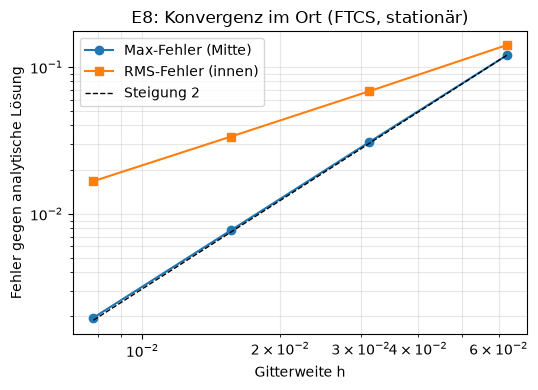

In [13]:
import os, time
import numpy as np
import matplotlib.pyplot as plt

def ftcs(N, r, steps):
    u = np.zeros((N, N)); u[0, :] = 100.0; v = u.copy()
    for _ in range(steps):
        v[1:-1, 1:-1] = u[1:-1, 1:-1] + r*(u[2:, 1:-1] + u[:-2, 1:-1] + u[1:-1, 2:] + u[1:-1, :-2] - 4.0*u[1:-1, 1:-1])
        u, v = v, u
    return u

def analytisch(N, nmax=2001):
    h = 1.0/(N - 1)
    y = (np.arange(N)*h)[:, None, None]          # Zeile i  <-> y = i*h (Zeile 0 = heiße Kante)
    x = (np.arange(N)*h)[None, :, None]          # Spalte j <-> x = j*h
    n = np.arange(1, nmax + 1, 2)[None, None, :] # nur ungerade n
    f = (np.exp(-n*np.pi*y) - np.exp(-n*np.pi*(2.0 - y))) / (1.0 - np.exp(-2.0*n*np.pi))
    return (400.0/(n*np.pi) * np.sin(n*np.pi*x) * f).sum(axis=2)

r = 0.2
print("Teil 1: stationäre Lösung gegen analytische Reihe (r=0.2)")
print(f"{'N':>4} {'h':>9} {'Schritte':>9} {'RMS_Fehler':>11} {'Max_Fehler_Mitte':>17} {'Verh.RMS':>9} {'Verh.Mitte':>10} {'Rechenzeit_s':>12}")
vorher = None
daten = {}
for N in (17, 33, 65, 129):
    h = 1.0/(N - 1)
    steps = int(14.0/(r*2*np.pi**2*h**2))
    t0 = time.time()
    u = ftcs(N, r, steps)
    a = analytisch(N)
    d = np.abs(u - a)
    rms = np.sqrt((d[1:-1, 1:-1]**2).mean())
    k = slice(int(0.25/h), int(0.75/h) + 1)
    mitte = d[k, k].max()
    verh = (vorher[0]/rms, vorher[1]/mitte) if vorher else (float("nan"), float("nan"))
    print(f"{N:>4} {h:>9.5f} {steps:>9} {rms:>11.3e} {mitte:>17.3e} {verh[0]:>9.2f} {verh[1]:>10.2f} {time.time()-t0:>12.1f}")
    vorher = (rms, mitte)
    daten[N] = (rms, mitte)
print("Erwartung bei Ordnung 2 im Ort: Verhältnis ≈ 4 pro Halbierung von h (Mitte); RMS kann wegen der Ecken abweichen.")

print()
print("Teil 2: Stabilität - größter Betrag |u| nach k Schritten (N=33)")
schritte = [50, 100, 200, 300]
print(f"{'r':>6} " + " ".join(f"{k:>12}" for k in schritte))
with np.errstate(all="ignore"):
    for rr in (0.20, 0.24, 0.25, 0.26, 0.30):
        zeilen = []
        u = np.zeros((33, 33)); u[0, :] = 100.0; v = u.copy()
        for s in range(1, max(schritte) + 1):
            v[1:-1, 1:-1] = u[1:-1, 1:-1] + rr*(u[2:, 1:-1] + u[:-2, 1:-1] + u[1:-1, 2:] + u[1:-1, :-2] - 4.0*u[1:-1, 1:-1])
            u, v = v, u
            if s in schritte:
                zeilen.append(np.abs(u).max())
        print(f"{rr:>6.2f} " + " ".join(f"{z:>12.3e}" for z in zeilen))
print("Erwartung: stabil für r ≤ 0.25 (|u| bleibt ≤ 100); r > 0.25 wächst |u| exponentiell.")

Ns = sorted(daten)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog([1.0/(N - 1) for N in Ns], [daten[N][1] for N in Ns], marker="o", label="Max-Fehler (Mitte)")
ax.loglog([1.0/(N - 1) for N in Ns], [daten[N][0] for N in Ns], marker="s", label="RMS-Fehler (innen)")
h0 = 1.0/(Ns[0] - 1)
ax.loglog([h0, 1.0/(Ns[-1] - 1)], [daten[Ns[0]][1], daten[Ns[0]][1]*(1.0/(Ns[-1] - 1)/h0)**2], "k--", lw=1, label="Steigung 2")
ax.set_xlabel("Gitterweite h"); ax.set_ylabel("Fehler gegen analytische Lösung")
ax.set_title("E8: Konvergenz im Ort (FTCS, stationär)"); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.savefig(os.path.expanduser("~/waerme/results/e8_konvergenz_2026-11-01.png"), dpi=150)
plt.show()

    N   s_Fit  S_max=1/s   P:            4             8            12            24            36            48
 2048  0.0841       11.9                 -    4.91/ 5.04    6.32/ 6.23    8.31/ 8.18    9.11/ 9.13    9.61/ 9.69
 4096  0.0651       15.4                 -    5.84/ 5.49    7.23/ 6.99   10.02/ 9.61   11.11/10.98   11.30/11.82
 8192  0.0599       16.7        3.51/ 3.39    6.44/ 5.64    8.49/ 7.23   10.91/10.10             -   11.53/12.58


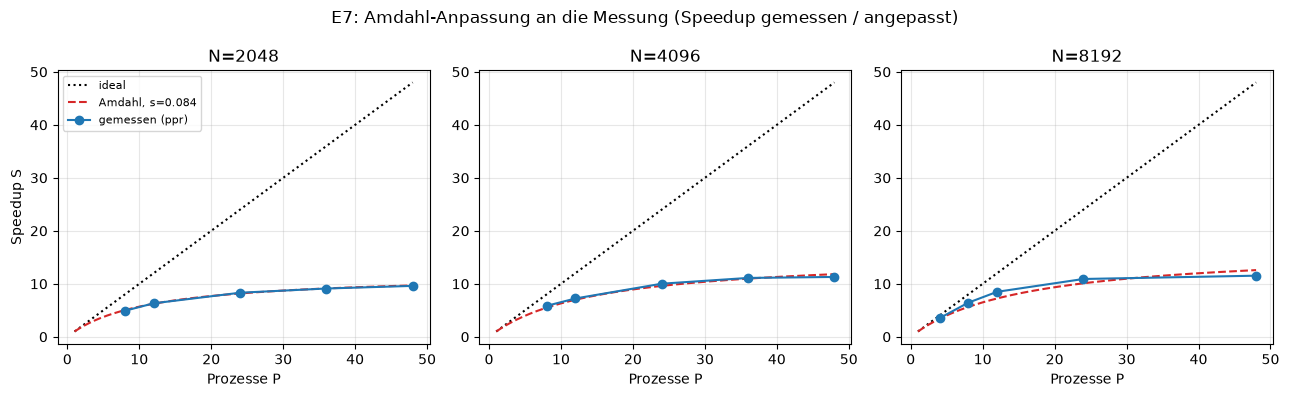

Tabelle: je Spalte 'S gemessen / S Amdahl'. s ist ein Anpassungsparameter, nicht der gemessene serielle Anteil.


In [14]:
import os, csv, glob
import numpy as np
import matplotlib.pyplot as plt

R = os.path.expanduser("~/waerme/results/")
BASIS = {2048: 1.3309, 4096: 5.1694, 8192: 21.6662}   # Referenz: Numba-Baseline (N=2048, 4096) bzw. Median P=1 aus E1 (N=8192)

def lade(files, nur_P=None):
    d = {}
    for f in files:
        with open(f) as fh:
            for z in csv.DictReader(fh):
                P = int(z["P"])
                if nur_P is not None and P not in nur_P:
                    continue
                d.setdefault((P, int(z["N"])), []).append(float(z["zeit_s"]))
    return d

d = lade([R+"e2d_ppr_2026-11-01.csv"] + sorted(glob.glob(R+"e2c_ppr_P*_2026-11-01.csv")), nur_P=(4, 8, 12, 24, 36))
d.update(lade([R+"e1_groesse_2026-11-01.csv"], nur_P=(48,)))

def amdahl(P, s):
    return 1.0/(s + (1.0 - s)/P)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
print(f"{'N':>5} {'s_Fit':>7} {'S_max=1/s':>10}   P: " + "  ".join(f"{p:>12}" for p in (4, 8, 12, 24, 36, 48)))
for a, N in zip(ax, (2048, 4096, 8192)):
    Ps = sorted(P for (P, n) in d if n == N)
    S = np.array([BASIS[N]/np.median(d[(P, N)]) for P in Ps]); P = np.array(Ps)
    ss = np.linspace(0.0, 0.5, 50001)
    s = min(ss, key=lambda x: ((S - amdahl(P, x))**2).sum())
    zeile = {p: f"{so:5.2f}/{amdahl(p, s):5.2f}" for p, so in zip(Ps, S)}
    print(f"{N:>5} {s:>7.4f} {1/s:>10.1f}      " + "  ".join(f"{zeile.get(p, '-'):>12}" for p in (4, 8, 12, 24, 36, 48)))
    pp = np.linspace(1, 48, 200)
    a.plot(pp, pp, "k:", label="ideal"); a.plot(pp, amdahl(pp, s), "--", color="#d62728", label=f"Amdahl, s={s:.3f}")
    a.plot(P, S, "o-", color="#1f77b4", label="gemessen (ppr)")
    a.set_title(f"N={N}"); a.set_xlabel("Prozesse P"); a.grid(alpha=0.3)
ax[0].set_ylabel("Speedup S"); ax[0].legend(fontsize=8)
plt.suptitle("E7: Amdahl-Anpassung an die Messung (Speedup gemessen / angepasst)")
plt.tight_layout()
plt.savefig(R+"e7_amdahl_2026-11-01.png", dpi=150)
plt.show()
print("Tabelle: je Spalte 'S gemessen / S Amdahl'. s ist ein Anpassungsparameter, nicht der gemessene serielle Anteil.")

--- N=2048, P=1: n=200 Läufe ---
  min 1.3017  median 2.2070  max 2.2241 s
  Referenz (schnellste 10 %): 1.3259 s, Schwelle 1,15x = 1.5248 s
  langsame Läufe: 149 von 200 (74.5 %)
  Median langsam 2.2092 s = 1.66x der schnellen (1.3341 s)
  Wechsel schnell/langsam: 74 (bei unabhängigen Läufen erwartet ≈ 75.6)
  längste Serie langsam: 14, längste Serie schnell: 3
--- N=4096, P=4: n=200 Läufe ---
  min 1.8876  median 2.5161  max 2.6311 s
  Referenz (schnellste 10 %): 1.9180 s, Schwelle 1,15x = 2.2057 s
  langsame Läufe: 119 von 200 (59.5 %)
  Median langsam 2.5445 s = 1.30x der schnellen (1.9623 s)
  Wechsel schnell/langsam: 93 (bei unabhängigen Läufen erwartet ≈ 95.9)
  längste Serie langsam: 11, längste Serie schnell: 5


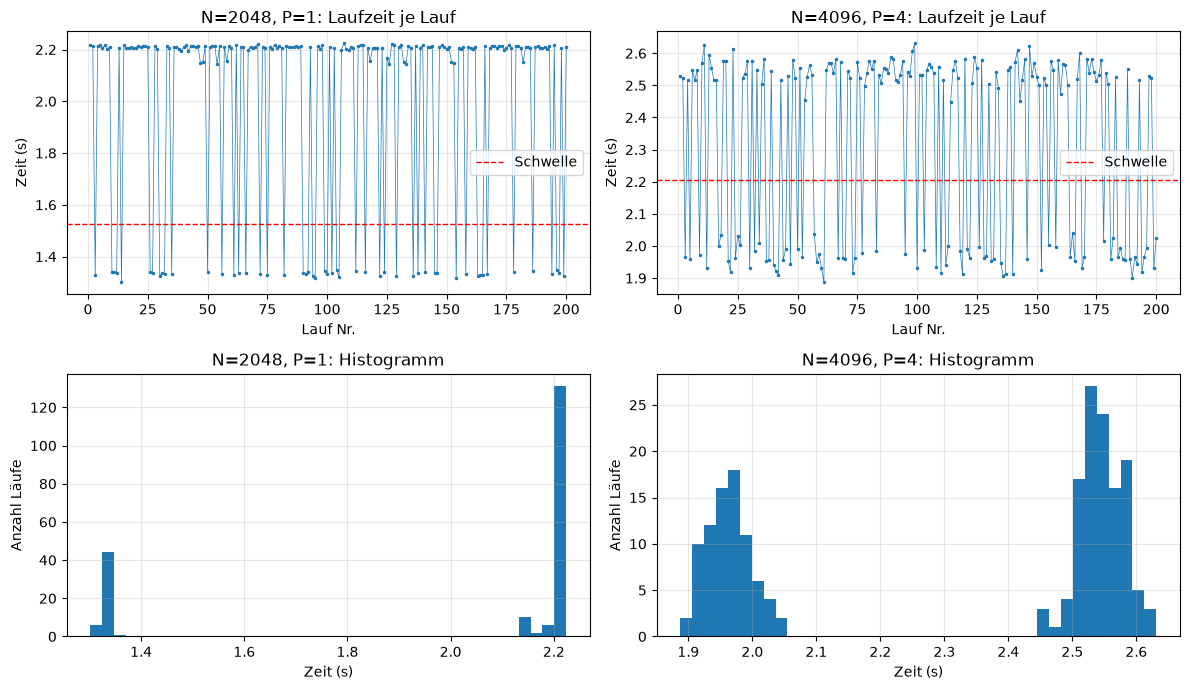

In [16]:
import os, csv
import numpy as np
import matplotlib.pyplot as plt

R = os.path.expanduser("~/waerme/results/")
tests = [("N=2048, P=1", R+"e13_N2048_P1_2026-11-01.csv"),
         ("N=4096, P=4", R+"e13_N4096_P4_2026-11-01.csv")]

def laengster_lauf(b):
    best = cur = 0
    for x in b:
        cur = cur + 1 if x else 0
        best = max(best, cur)
    return best

fig, ax = plt.subplots(2, len(tests), figsize=(12, 7))
for col, (name, f) in enumerate(tests):
    with open(f) as fh:
        t = np.array([float(z["zeit_s"]) for z in csv.DictReader(fh)])
    n = len(t)
    ref = np.median(np.sort(t)[:max(5, n//10)])        # Referenz: Median der schnellsten 10 %
    langsam = t > 1.15*ref                              # Schwelle: 15 % über Referenz
    p = langsam.mean()
    wechsel = int((langsam[1:] != langsam[:-1]).sum())
    erwartet = 2*p*(1 - p)*(n - 1)                      # erwartete Wechsel bei unabhängigen Läufen
    print(f"--- {name}: n={n} Läufe ---")
    print(f"  min {t.min():.4f}  median {np.median(t):.4f}  max {t.max():.4f} s")
    print(f"  Referenz (schnellste 10 %): {ref:.4f} s, Schwelle 1,15x = {1.15*ref:.4f} s")
    print(f"  langsame Läufe: {langsam.sum()} von {n} ({100*p:.1f} %)")
    if langsam.any() and (~langsam).any():
        print(f"  Median langsam {np.median(t[langsam]):.4f} s = {np.median(t[langsam])/np.median(t[~langsam]):.2f}x der schnellen ({np.median(t[~langsam]):.4f} s)")
    print(f"  Wechsel schnell/langsam: {wechsel} (bei unabhängigen Läufen erwartet ≈ {erwartet:.1f})")
    print(f"  längste Serie langsam: {laengster_lauf(langsam)}, längste Serie schnell: {laengster_lauf(~langsam)}")
    ax[0, col].plot(range(1, n + 1), t, ".-", lw=0.5, ms=3)
    ax[0, col].axhline(1.15*ref, color="r", ls="--", lw=1, label="Schwelle")
    ax[0, col].set_title(f"{name}: Laufzeit je Lauf"); ax[0, col].set_xlabel("Lauf Nr."); ax[0, col].set_ylabel("Zeit (s)")
    ax[0, col].legend(); ax[0, col].grid(alpha=0.3)
    ax[1, col].hist(t, bins=40, color="#1f77b4"); ax[1, col].set_title(f"{name}: Histogramm")
    ax[1, col].set_xlabel("Zeit (s)"); ax[1, col].set_ylabel("Anzahl Läufe"); ax[1, col].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(R+"e13_variabilitaet_2026-11-01.png", dpi=150)
plt.show()

n=200 Läufe, Referenz schnell 1.3262 s, langsam: 140 (70.0 %)

nach CPU-Kern (Start)
        Wert  Läufe  langsam  Anteil_%  Median_s
           0    193      135      69.9    2.2077
           1      7        5      71.4    2.1984

nach Taktfrequenz am Start (MHz)
        Wert  Läufe  langsam  Anteil_%  Median_s
     3408553      1        1     100.0    2.2273
     3413976      1        1     100.0    2.2075
     3433594      1        1     100.0    2.2094
     3434153      1        1     100.0    2.2110
     3435206      1        1     100.0    2.2093
     3436357      1        1     100.0    2.2123
     3437691      1        0       0.0    1.3219
     3438110      1        0       0.0    1.3362
     3441234      1        0       0.0    1.3320
     3442015      1        1     100.0    2.2109
     3442067      1        1     100.0    2.2047
     3442266      1        0       0.0    1.3300
     3453626      1        1     100.0    2.2168
     3470245      1        0       0.0    1.3313

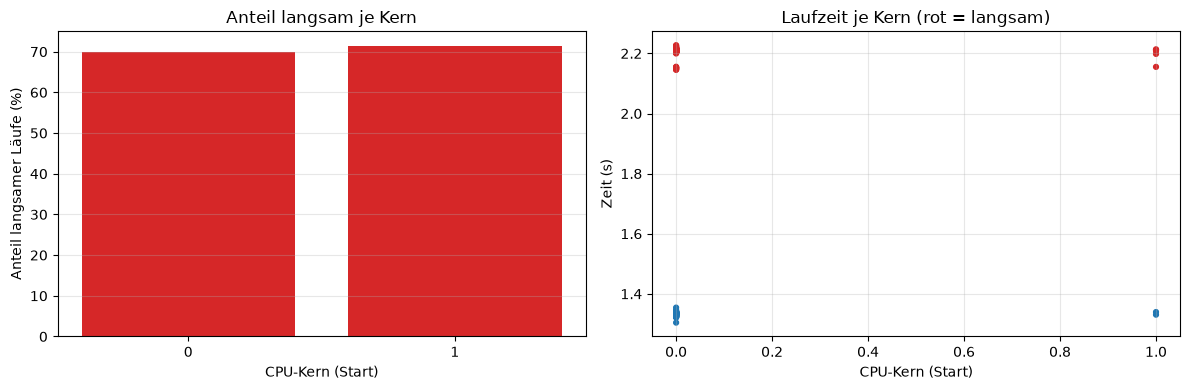

In [17]:
import os, csv
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt

R = os.path.expanduser("~/waerme/results/")
with open(R+"e13b_cpu_N2048_P1_2026-11-01.csv") as fh:
    z = list(csv.DictReader(fh))
t = np.array([float(a["zeit_s"]) for a in z])
n = len(t)
ref = np.median(np.sort(t)[:max(5, n//10)])
langsam = t > 1.15*ref
print(f"n={n} Läufe, Referenz schnell {ref:.4f} s, langsam: {langsam.sum()} ({100*langsam.mean():.1f} %)")

def tabelle(titel, schluessel):
    d = defaultdict(lambda: [0, 0, []])
    for a, tt, l in zip(z, t, langsam):
        k = schluessel(a)
        d[k][0] += 1; d[k][1] += int(l); d[k][2].append(tt)
    print(f"\n{titel}")
    print(f"{'Wert':>12} {'Läufe':>6} {'langsam':>8} {'Anteil_%':>9} {'Median_s':>9}")
    for k in sorted(d, key=lambda x: (str(x).zfill(8))):
        m, s, ts = d[k]
        print(f"{str(k):>12} {m:>6} {s:>8} {100*s/m:>9.1f} {np.median(ts):>9.4f}")
    return d

d_cpu = tabelle("nach CPU-Kern (Start)", lambda a: a["cpu_start"])
tabelle("nach Taktfrequenz am Start (MHz)", lambda a: a["mhz_start"])
tabelle("nach Taktfrequenz am Ende (MHz)", lambda a: a["mhz_ende"])
tabelle("nach Sockel", lambda a: a["sockel"])
tabelle("nach Zwillingskern-Liste", lambda a: a["zwilling"])
wandert = np.array([a["cpu_start"] != a["cpu_ende"] for a in z])
print(f"\nKern gewechselt (Start != Ende): langsam {100*wandert[langsam].mean() if langsam.any() else 0:.1f} %, schnell {100*wandert[~langsam].mean() if (~langsam).any() else 0:.1f} %")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cores = sorted(d_cpu, key=lambda k: int(k))
ax[0].bar([str(k) for k in cores], [100*d_cpu[k][1]/d_cpu[k][0] for k in cores], color="#d62728")
ax[0].set_xlabel("CPU-Kern (Start)"); ax[0].set_ylabel("Anteil langsamer Läufe (%)")
ax[0].set_title("Anteil langsam je Kern"); ax[0].grid(axis="y", alpha=0.3)
ax[1].scatter([int(a["cpu_start"]) for a in z], t, c=np.where(langsam, "#d62728", "#1f77b4"), s=12)
ax[1].set_xlabel("CPU-Kern (Start)"); ax[1].set_ylabel("Zeit (s)"); ax[1].set_title("Laufzeit je Kern (rot = langsam)")
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(R+"e13b_cpu_2026-11-01.png", dpi=150)
plt.show()